---
short_title: Basics
execute:
  skip: true
downloads:
  - url: https://colab.research.google.com/github/mibur1/psy300/blob/main/book/solutions/solutions_1.ipynb
    title: Open in Colab
  - file: solutions_1.ipynb
    title: Download notebook
---

# 🔑 Solutions: Machine Learning Basics

## Exercise 1: Psy111 Recap

Remember the materials from last semester. Can you implement regression models using  `statsmodels` as well as the `sklearn` package? Which degree of polynomial will be most suited for the synthetic data?

Please plot the result


                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.832
Model:                            OLS   Adj. R-squared:                  0.828
Method:                 Least Squares   F-statistic:                     240.0
Date:                Mon, 12 Oct 2026   Prob (F-statistic):           2.76e-38
Time:                        13:42:47   Log-Likelihood:                -75.074
No. Observations:                 100   AIC:                             156.1
Df Residuals:                      97   BIC:                             164.0
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0738      0.078      0.945      0.3

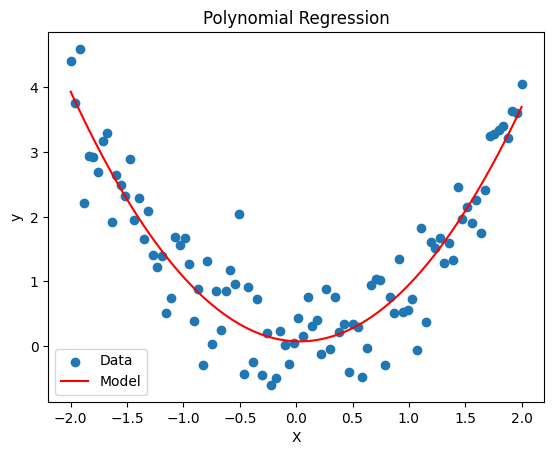

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

# Generate synthetic data
n_samples = 100
X = np.linspace(-2, 2, n_samples).reshape(-1, 1)
y = X**2 + np.random.normal(scale=0.5, size=X.shape)

# TODO: Statsmodels
poly = PolynomialFeatures(degree=2)
X_poly = poly.fit_transform(X)
model = sm.OLS(y, X_poly) 
fit = model.fit()
print(fit.summary())

# TODO: Numpy
coefs = np.polyfit(X.ravel(), y.ravel(), deg=2) 
y_np = np.polyval(coefs, X.ravel()) # highest power first: [b2, b1, b0]
print("\nNumpy coefficients:", coefs)

# TODO: Scikit-learn
X_poly = poly.fit_transform(X)
model = LinearRegression()
model.fit(X_poly, y)

# TODO: Plot the predictions
fig, ax = plt.subplots()
ax.scatter(X, y, label='Data')
ax.plot(X, model.predict(X_poly), label='Model', color='red')
ax.set(xlabel='X', ylabel='y', title='Polynomial Regression')
ax.legend();

## Exercise 2: Bias-variance Tradeoff

To get a better understanding of the bias-variance tradeoff, we will fit polynomial regression models to synthetic data from a known function, $y = \sin(x) + \varepsilon$.

Please perform the following tasks:

1. Visualize the data. Which model do you think would be optimal?
2. Split the data into a training set (70%) and a test set (30%). Use `random_state=42` so that your results are reproducible.
3. Fit polynomial regression models for degrees 1 to 12 and calculate the training and test MSE for each of them
4. Plot the training and test MSE against the polynomial degree
5. Which degree has the lowest test MSE? Does it match your guess from task 1? Now repeat the split with a few different values for `random_state`. Does the best degree change? How much does the test MSE vary?

**Bonus:** Because we know the true function, we can also measure bias and variance directly, just like in the [bias-variance session](../1_basics/2_bias_variance.md). Simulate many datasets with the same `X` but new noise, fit a model of each degree to each dataset, and calculate bias² and variance of the predictions.

*Hint: You can split the data with the `train_test_split()` function from `sklearn.model_selection`.*

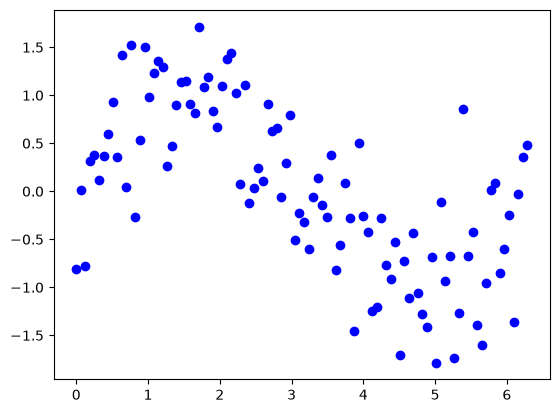

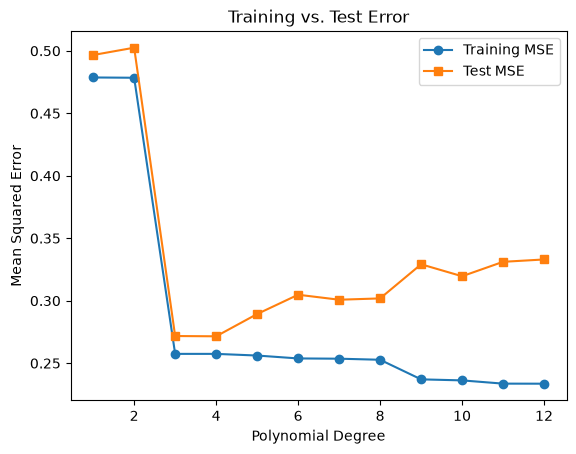

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split

# Generate synthetic data
np.random.seed(55)
n_samples = 100
X = np.linspace(0, 2*np.pi, n_samples).reshape(-1, 1)  # Reshape for sklearn
y = np.sin(X) + np.random.normal(scale=0.5, size=X.shape)

# 1. Visualize the data
plt.scatter(X, y, label='Data', color='blue')

# 2. Split the data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# 3. Fit polynomial regression models for degrees 1 to 12
degrees = range(1, 13)
train_errors = []
test_errors = []

for degree in degrees:
    # Transform the features into polynomial features
    poly = PolynomialFeatures(degree=degree)
    X_train_poly = poly.fit_transform(X_train)
    X_test_poly = poly.transform(X_test)

    # Fit a linear regression model on the polynomial features
    model = LinearRegression()
    model.fit(X_train_poly, y_train)

    # Predict on both training and test sets
    y_train_pred = model.predict(X_train_poly)
    y_test_pred = model.predict(X_test_poly)

    # Calculate mean squared errors
    train_errors.append(mean_squared_error(y_train, y_train_pred))
    test_errors.append(mean_squared_error(y_test, y_test_pred))

# 4. Plot the training and test MSE against polynomial degree
fig, ax = plt.subplots()
ax.plot(degrees, train_errors, marker='o', label='Training MSE')
ax.plot(degrees, test_errors, marker='s', label='Test MSE')
ax.set(xlabel="Polynomial Degree", ylabel="Mean Squared Error", title="Training vs. Test Error")
ax.legend();

random_state=0: best degree = 3, test MSE = 0.204
random_state=1: best degree = 3, test MSE = 0.260
random_state=2: best degree = 3, test MSE = 0.398
random_state=3: best degree = 5, test MSE = 0.307
random_state=4: best degree = 4, test MSE = 0.373


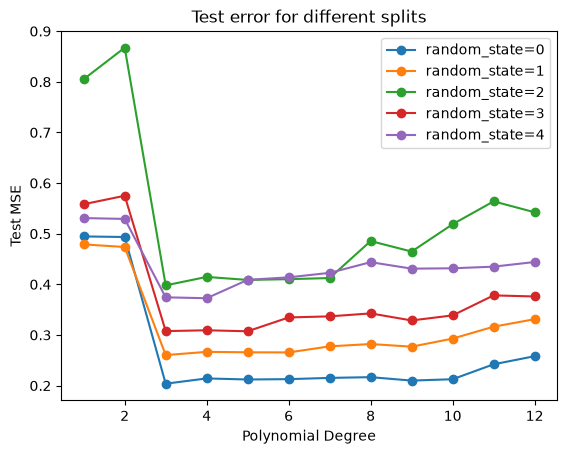

In [ ]:
# 5. Repeat the split with different values for random_state
fig, ax = plt.subplots()

for random_state in [0, 1, 2, 3, 4]:
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=random_state)
    test_errors = []

    for degree in degrees:
        poly = PolynomialFeatures(degree=degree)
        model = LinearRegression().fit(poly.fit_transform(X_train), y_train)
        test_errors.append(mean_squared_error(y_test, model.predict(poly.transform(X_test))))

    best = degrees[np.argmin(test_errors)]
    print(f"random_state={random_state}: best degree = {best}, test MSE = {min(test_errors):.3f}")
    ax.plot(degrees, test_errors, marker='o', label=f"random_state={random_state}")

ax.set(xlabel="Polynomial Degree", ylabel="Test MSE", title="Test error for different splits")
ax.legend();

With `random_state=42`, degrees 3 and 4 have the lowest test MSE (both 0.272). This matches what we would expect from the scatterplot: between $0$ and $2\pi$, the sine curve has two bends, which a cubic polynomial can capture. The training MSE, in contrast, keeps decreasing with every additional degree.

With other splits, the best degree varies between 3 and 5, and the lowest test MSE between about 0.20 and 0.40. A single train/test split therefore gives quite a noisy estimate of the test error, which is why we will use resampling methods such as cross-validation in the next session.

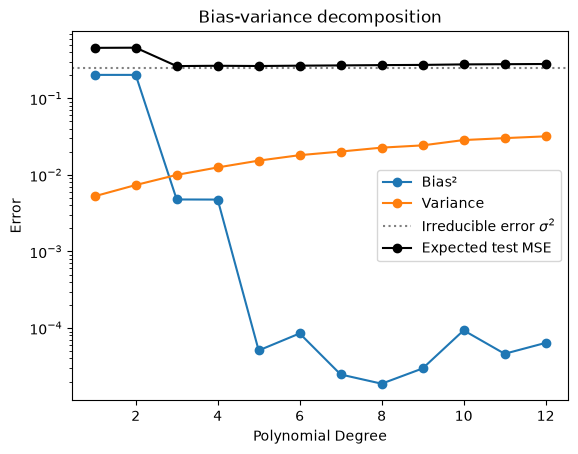

In [ ]:
# Bonus: Estimate bias² and variance by simulating many datasets
rng = np.random.default_rng(0)
f_true = np.sin(X).ravel()  # the true function at each x
sigma = 0.5                 # the noise level used to generate the data
n_sims = 500

bias2, variance = [], []

for degree in degrees:
    poly = PolynomialFeatures(degree=degree)
    X_poly = poly.fit_transform(X)

    # Fit one model per simulated dataset (same x, new noise) and store its predictions
    preds = np.empty((n_sims, len(X)))
    for s in range(n_sims):
        y_sim = f_true + rng.normal(0, sigma, size=len(X))
        preds[s] = LinearRegression().fit(X_poly, y_sim).predict(X_poly)

    bias2.append(np.mean((preds.mean(axis=0) - f_true) ** 2))
    variance.append(np.mean(preds.var(axis=0)))

total = np.array(bias2) + np.array(variance) + sigma**2

fig, ax = plt.subplots()
ax.plot(degrees, bias2, marker='o', label='Bias²')
ax.plot(degrees, variance, marker='o', label='Variance')
ax.axhline(sigma**2, color='grey', ls=':', label='Irreducible error $\\sigma^2$')
ax.plot(degrees, total, marker='o', color='k', label='Expected test MSE')
ax.set(xlabel="Polynomial Degree", ylabel="Error", yscale="log", title="Bias-variance decomposition")
ax.legend();

Bias² drops sharply at degree 3, as soon as the model can follow both bends of the sine curve. It drops a second time at degree 5, because a sine is not exactly a cubic, so degrees 3 and 4 still have a small bias. The variance, in contrast, grows steadily with every additional degree. Their sum, the expected test MSE, is lowest at degree 3 (0.265), with degree 5 almost as good (0.265), and it never drops below the irreducible error $\sigma^2 = 0.25$.

## Exercise 3: Resampling Methods

The dataset we are using for the exercise is the [California Housing Dataset](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.fetch_california_housing.html). It contains 20640 samples and 8 features. In this dataset, we have information regarding the demography (income, population, house occupancy) in the districts, the location of the districts (latitude, longitude), and general information regarding the house in the districts (number of rooms, number of bedrooms, age of the house). Since these statistics are at the granularity of the district, they correspond to averages or medians.

Familiarize yourself with the dataset by exploring the documentation and looking at the data. What are the features and target?

*Hints:*
- *`print(data.DESCR)` prints the documentation of the dataset*
- *`df.head()` shows the first rows of the DataFrame, and `df.describe()` gives summary statistics for every column*
- *The names of the features and the target are stored in `data.feature_names` and `data.target_names`*

In [3]:
from sklearn.datasets import fetch_california_housing

data = fetch_california_housing(as_frame=True)
df = data.frame

df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


The dataset has 8 features (`MedInc`, `HouseAge`, `AveRooms`, `AveBedrms`, `Population`, `AveOccup`, `Latitude`, `Longitude`). The target is `MedHouseVal`, the median house value of each district in units of $100,000.

Let’s have a quick look at the distribution of these features by plotting their histograms.

*Hint: DataFrames have a `.hist()` method that plots a histogram for every column. Use its `figsize` and `bins` arguments to make the plot readable.*

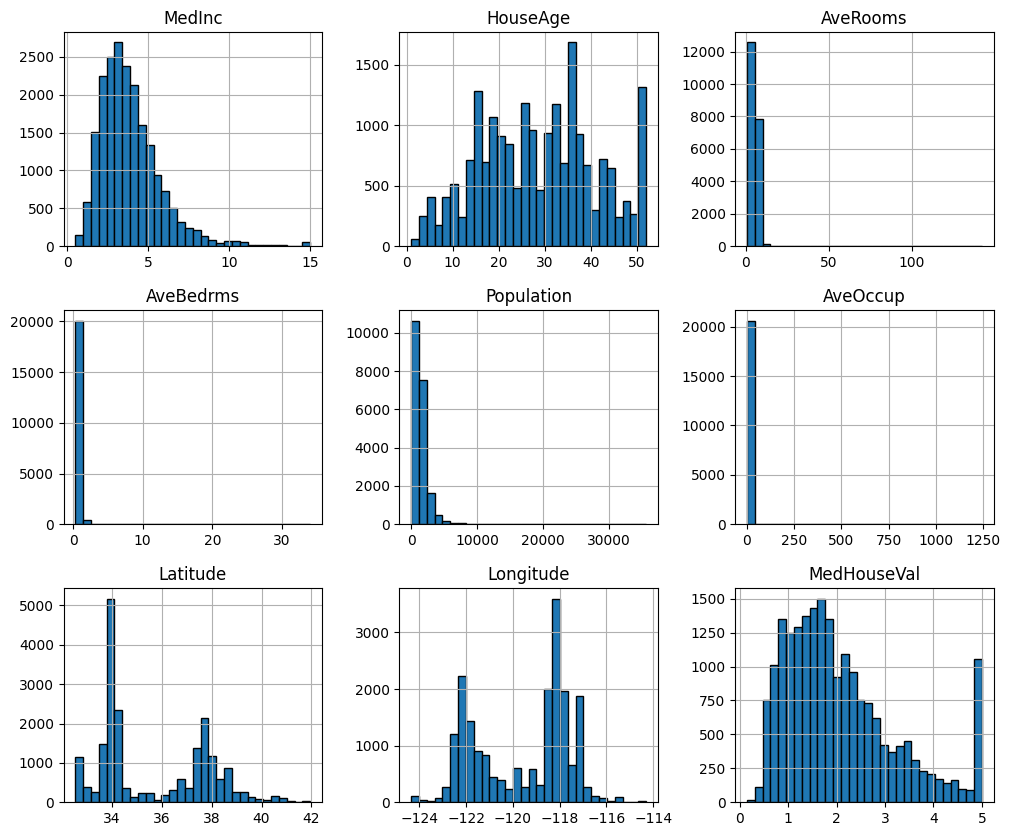

In [4]:
df.hist(figsize=(12, 10), bins=30, edgecolor="black");

1. Prepare the data for cross validation. This will require you to have a variable (e.g. `X`) for the features and a variable for the target (e.g. `y`).
2. Set up a k-fold cross validation for a linear regression
    - Choose an appropriate k
    - Define the model
    - Perform cross validation
    - Use the mean squared error (MSE) to assess model performance
3. Visualize which rows end up in the validation fold in each of the 5 rounds, once with `KFold(n_splits=5)` and once with `KFold(n_splits=5, shuffle=True)`. Then run the cross-validation with both splitters and compare the MSE of the individual folds. What do you notice?

*Hints:*
- *For 1: You can achieve this by e.g. creating them from the DataFrame, or by using the `return_X_y` parameter on the [`fetch_california_housing()` function](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.fetch_california_housing.html)*
- *For 2: You can use the `LinearRegression()` model from sklearn. You can further evaluate the model and specify the (negative) MSE as a performance measure in `cross_val_score()`*
- *For 3: Have a look at the `plot_cv_indices()` function in the [scikit-learn example on visualizing cross-validation behavior](https://scikit-learn.org/stable/auto_examples/model_selection/plot_cv_indices.html) as an example. A simpler version: create an array of zeros with one row per fold and one column per observation, set the validation rows of each fold to 1, and plot it with `plt.imshow(..., aspect='auto')`.*
- *The [scikit-learn user guide on cross-validation](https://scikit-learn.org/stable/modules/cross_validation.html) explains all splitters and functions used in this exercise, with examples.*

In [5]:
# TODO: Prepare data
X, y = fetch_california_housing(return_X_y=True)

In [ ]:
from sklearn.model_selection import KFold
from sklearn.linear_model import LinearRegression 
from sklearn.model_selection import cross_val_score 

# TODO: Implement CV
k_fold = KFold(n_splits=5, shuffle=True, random_state=42)  # shuffle, since the rows are ordered
model = LinearRegression()

neg_mse = cross_val_score(model, X, y, cv=k_fold, scoring='neg_mean_squared_error')
mse = -neg_mse

print(f"Average MSE:       {mse.mean()}")
print(f"MSE for each fold: {mse}")

Average MSE:       0.5305724639238875
MSE for each fold: [0.5558916  0.52765625 0.50928321 0.50485078 0.55518048]


Without shuffling: [0.485 0.622 0.646 0.543 0.495]   mean: 0.558
With shuffling:    [0.556 0.528 0.509 0.505 0.555]   mean: 0.531


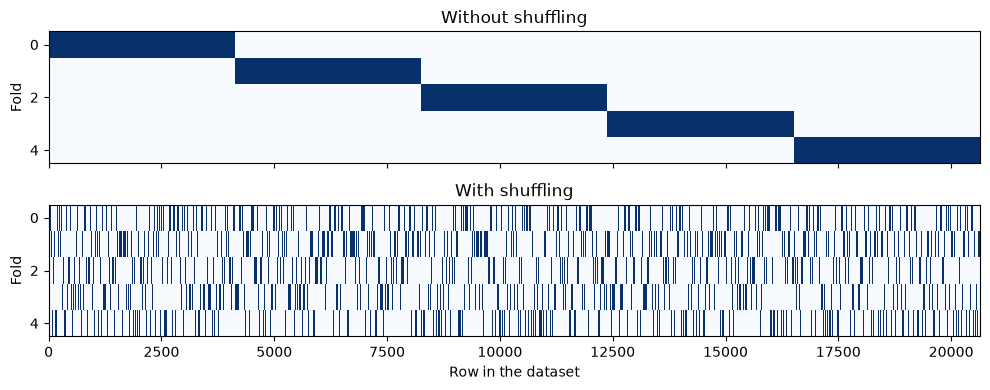

In [ ]:
# 3. Visualize the folds with and without shuffling and compare the fold MSEs
import numpy as np
import matplotlib.pyplot as plt

kf = KFold(n_splits=5)
kf_shuffled = KFold(n_splits=5, shuffle=True, random_state=42)

# Mark the validation rows of each fold with 1 (training rows stay 0)
folds = np.zeros((5, len(y)))
for fold, (train_idx, val_idx) in enumerate(kf.split(X)):
    folds[fold, val_idx] = 1

folds_shuffled = np.zeros((5, len(y)))
for fold, (train_idx, val_idx) in enumerate(kf_shuffled.split(X)):
    folds_shuffled[fold, val_idx] = 1

# Plot the folds
fig, ax = plt.subplots(2, 1, figsize=(10, 4), sharex=True)

ax[0].imshow(folds, aspect="auto", cmap="Blues", interpolation="nearest")
ax[0].set(title="Without shuffling", ylabel="Fold")

ax[1].imshow(folds_shuffled, aspect="auto", cmap="Blues", interpolation="nearest")
ax[1].set(title="With shuffling", xlabel="Row in the dataset", ylabel="Fold")

plt.tight_layout()

# Compare the MSE of the individual folds
mse = -cross_val_score(LinearRegression(), X, y, cv=kf, scoring='neg_mean_squared_error')
mse_shuffled = -cross_val_score(LinearRegression(), X, y, cv=kf_shuffled, scoring='neg_mean_squared_error')

print(f"Without shuffling: {np.round(mse, 3)}   mean: {mse.mean():.3f}")
print(f"With shuffling:    {np.round(mse_shuffled, 3)}   mean: {mse_shuffled.mean():.3f}")

Without shuffling, each validation fold is a block of about 4100 consecutive rows. The rows of the dataset are not in random order: neighbouring rows tend to be districts from the same region. The folds therefore cover different parts of California, with average house values between 1.68 and 2.36 (in units of $100,000). Each model is validated on a region that is underrepresented in its training data, and the fold MSEs vary between 0.49 and 0.65.

With shuffling, every fold is a random mix of all districts. The fold MSEs are much more similar (0.51 to 0.56), and the mean MSE is slightly lower. In this dataset the difference is moderate, but as you saw with the iris data in the session, it can also be dramatic.

## Exercise 4: LOOCV

1. Draw a random subset of 5000 observations (LOOCV on all 20640 observations would take a while). Run LOOCV on this subset and compare the average MSE with a 5-fold CV on the same subset.
2. Get the minimum and maximum MSE value. Discuss the range!
3. Plot the MSE values in a histogram (the x-range should be from 0 to 6)
4. Calculate the median MSE and discuss if it might be a more appropriate measure than the mean

*Hint: You can draw a random subset of row indices with `np.random.default_rng(42).choice(len(y), size=5000, replace=False)`.*

Average MSE (LOOCV):  0.568
Average MSE (5-fold): 0.581
Minimum MSE:          1.89e-08
Maximum MSE:          115.4
Median MSE:           0.166


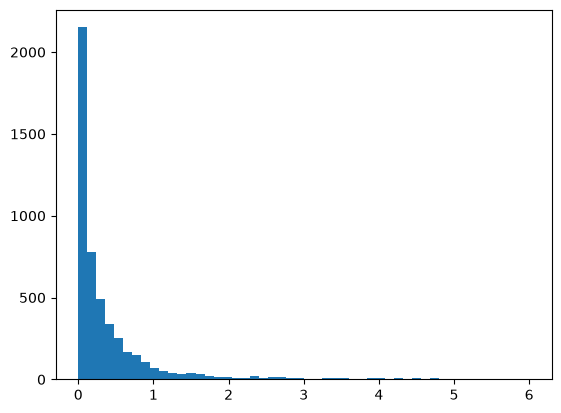

In [ ]:
# TODO: Implement LOOCV
import numpy as np
from matplotlib import pyplot as plt
from sklearn.model_selection import LeaveOneOut

# 1. Random subset of 5000 observations
rng = np.random.default_rng(42)
idx = rng.choice(len(y), size=5000, replace=False)
X_sub, y_sub = X[idx], y[idx]

model = LinearRegression()

# LOOCV
mse = -cross_val_score(model, X_sub, y_sub, cv=LeaveOneOut(), scoring='neg_mean_squared_error')

# 5-fold CV on the same subset for comparison
k_fold = KFold(n_splits=5, shuffle=True, random_state=42)
mse_kfold = -cross_val_score(model, X_sub, y_sub, cv=k_fold, scoring='neg_mean_squared_error')

# 2. and 4. Get MSE metrics
print(f"Average MSE (LOOCV):  {mse.mean():.3f}")
print(f"Average MSE (5-fold): {mse_kfold.mean():.3f}")
print(f"Minimum MSE:          {mse.min():.2e}")
print(f"Maximum MSE:          {mse.max():.1f}")
print(f"Median MSE:           {np.median(mse):.3f}")

# 3. Plot MSE
plt.hist(mse, bins=50, range=(0, 6));

In [ ]:
# Which observation causes the largest error?
feature_names = fetch_california_housing().feature_names
worst = np.argmax(mse)
print(dict(zip(feature_names, X_sub[worst].round(1))))

{'MedInc': np.float64(1.6), 'HouseAge': np.float64(8.0), 'AveRooms': np.float64(7.6), 'AveBedrms': np.float64(1.0), 'Population': np.float64(1275.0), 'AveOccup': np.float64(63.8), 'Latitude': np.float64(34.0), 'Longitude': np.float64(-117.3)}


**1.** The average LOOCV MSE (0.568) is close to the 5-fold MSE on the same subset (0.581). Both estimate the same test error, LOOCV just needs 5000 instead of 5 model fits.

**2.** The individual MSE values range from almost 0 to over 100. Most observations are predicted reasonably well, but a few are predicted very badly. The worst one is a district with an average occupancy of 64 people per household, while 99% of all districts have fewer than 6 (probably a dormitory or a similar institution). The linear model has to extrapolate far beyond the typical data for this district.

**3.** The histogram shows a strongly right-skewed distribution: most squared errors are close to 0, with a long tail to the right.

**4.** The median (0.166) is much lower than the mean (0.568). It is robust to the few extreme errors, but it is not a good replacement for the MSE: squared errors are always right-skewed, so their median is systematically smaller than their mean, even without any outliers. It is better to report the mean, and to look at the observations with the largest errors (as we did above) to understand where the model fails.